In [8]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
df = pd.read_csv('Housing.csv')
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished



Mean Squared Error: 3675286604768.1855

R2 Score: 0.27287851871974633

Cross Validation Score: [  -7.61593137  -19.74065355  -27.89955146  -49.67362611  -50.62512199
  -85.32300629  -73.03459892 -234.71228268 -167.44821817  -38.99491977]

Average Score: -75.5067910318875


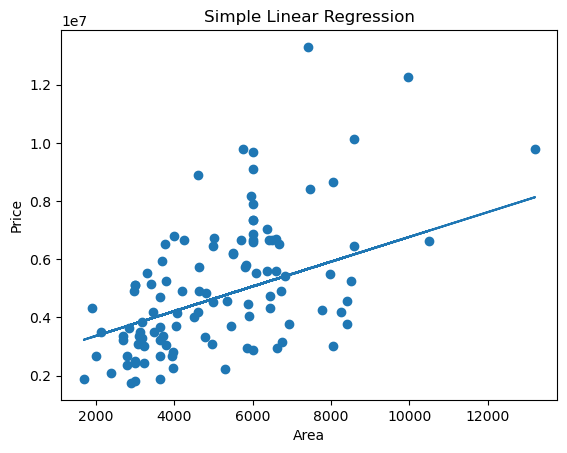

In [6]:
X = df[['area']]
Y = df['price']
X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size = 0.2,
    random_state = 42
)
model = LinearRegression()
model.fit(X_train, Y_train)
Y_pred = model.predict(X_test)
print(f'\nMean Squared Error: {mean_squared_error(Y_test, Y_pred)}')
print(f'\nR2 Score: {r2_score(Y_test, Y_pred)}')
scores = cross_val_score(
    model,
    X,
    Y,
    cv = 10,
    scoring = 'r2'
)
print(f'\nCross Validation Score: {scores}')
print(f'\nAverage Score: {scores.mean()}')

plt.scatter(X_test, Y_test)
plt.plot(X_test, Y_pred)

plt.xlabel('Area')
plt.ylabel('Price')
plt.title('Simple Linear Regression')
plt.show()

In [10]:
for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = LabelEncoder().fit_transform(df[col])

Xm = df.drop('price', axis = 1)
Ym = df['price']

Xm_train, Xm_test, Ym_train, Ym_test = train_test_split(
    Xm,
    Ym,
    test_size = 0.2,
    random_state = 42
)
model_m = LinearRegression()
model_m.fit(Xm_train, Ym_train)
Ym_pred = model_m.predict(Xm_test)
print(f'\nMean Squared Error: {mean_squared_error(Ym_pred, Ym_test)}')
print(f'\nR2 Score: {r2_score(Ym_pred, Ym_test)}')
scores = cross_val_score(
    model_m,
    Xm,
    Ym,
    cv = 10,
    scoring = 'r2'
)
print(f'\nCross Validation Scores: {scores}')
print(f'\nAverage Scores: {scores.mean()}')


Mean Squared Error: 1771751116594.0342

R2 Score: 0.2646568767358578

Cross Validation Scores: [  -3.27953292   -9.53624079  -14.79725802  -34.86401852  -57.8112305
  -83.23736042  -65.3268292  -117.14285737  -41.23160338  -11.34559623]

Average Scores: -43.85725273506763
